In [7]:
!pip install -q "transformers==5.17.0" "protobuf>=5.26.1,<6" "accelerate>=1.1.0" datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 80.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 79.4 MB/s eta 0:00:00:00:01


In [9]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import random
from collections import Counter
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.special import softmax
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
)

SEED = 42
MODEL_NAME = "answerdotai/ModernBERT-base"
DATASET_NAME = "clinc/clinc_oos"
DATASET_CONFIG = "plus"
MAX_LEN = 64
OUTPUT_DIR = "/kaggle/working/clinc_router"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: Tesla T4


In [11]:
raw = load_dataset(DATASET_NAME, DATASET_CONFIG)
raw = raw.rename_column("intent", "label")

LABEL_NAMES = raw["train"].features["label"].names
NUM_LABELS = len(LABEL_NAMES)
OOS_ID = LABEL_NAMES.index("oos")
ID2LABEL = dict(enumerate(LABEL_NAMES))
LABEL2ID = {n: i for i, n in ID2LABEL.items()}

print(raw)
print("Intents:", NUM_LABELS, "| oos id:", OOS_ID)
for split in raw:
    labels = np.array(raw[split]["label"])
    print(f"{split:<11} total={len(labels):<6} in-scope={(labels != OOS_ID).sum():<6} oos={(labels == OOS_ID).sum()}")

for ex in raw["train"].shuffle(seed=SEED).select(range(8)):
    print(f"{ID2LABEL[ex['label']]:<25} {ex['text']}")

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 15250
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 3100
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 5500
    })
})
Intents: 151 | oos id: 42
train       total=15250  in-scope=15000  oos=250
validation  total=3100   in-scope=3000   oos=100
test        total=5500   in-scope=4500   oos=1000
jump_start                how do i properly give my car a jump
change_volume             set the volume to 4 please
order_checks              order new checks, please
schedule_meeting          could you please schedule a meeting with carrie and lisa
change_speed              please increase the speed of your speech, it is too slow
no                        what you just said is wrong
cook_time                 how long does it take to bake a pork loin
alarm                     at 9 tomorrow, set off the alarm


In [12]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

tokenized = raw.map(
    lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN),
    batched=True,
    remove_columns=["text"],
)
train_ds, val_ds, test_ds = tokenized["train"], tokenized["validation"], tokenized["test"]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

Map:   0%|          | 0/15250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3100 [00:00<?, ? examples/s]

Map:   0%|          | 0/5500 [00:00<?, ? examples/s]

In [6]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)


def compute_metrics(p):
    return {"accuracy": float((p.predictions.argmax(-1) == p.label_ids).mean())}


args = TrainingArguments(
    output_dir="/kaggle/working/checkpoints",
    num_train_epochs=5,
    learning_rate=5e-5,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=128,
    warmup_steps=0.1,
    weight_decay=0.01,
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

trainer.train()

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.weight | MISSING    | 
classifier.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': None, 'bos_token_id': None}.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.351475,0.317262,0.919355
2,0.080732,0.226602,0.944839
3,0.013637,0.185428,0.957097
4,0.010990,0.174279,0.957742
5,0.001008,0.178532,0.956452


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1195, training_loss=0.455409638465199, metrics={'train_runtime': 197.5953, 'train_samples_per_second': 385.89, 'train_steps_per_second': 6.048, 'total_flos': 1165841476325832.0, 'train_loss': 0.455409638465199, 'epoch': 5.0})

In [7]:
def get_logits(ds):
    out = trainer.predict(ds)
    return np.asarray(out.predictions, dtype=np.float32), out.label_ids


def fit_temperature(logits, labels):
    lg = torch.tensor(logits)
    lb = torch.tensor(labels, dtype=torch.long)
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)

    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(lg / log_t.exp(), lb)
        loss.backward()
        return loss

    opt.step(closure)
    return float(log_t.exp().item())


val_logits, val_labels = get_logits(val_ds)
test_logits, test_labels = get_logits(test_ds)

TEMPERATURE = fit_temperature(val_logits, val_labels)
val_probs = softmax(val_logits / TEMPERATURE, axis=1)
test_raw = softmax(test_logits, axis=1)
test_probs = softmax(test_logits / TEMPERATURE, axis=1)
print("Temperature:", round(TEMPERATURE, 3))

Temperature: 1.101


test raw               overall_acc=0.9018  in_scope_acc=0.9622  oos_recall=0.6300  oos_precision=0.9692
test scaled            overall_acc=0.9018  in_scope_acc=0.9622  oos_recall=0.6300  oos_precision=0.9692
ECE raw=0.0246  scaled=0.0156


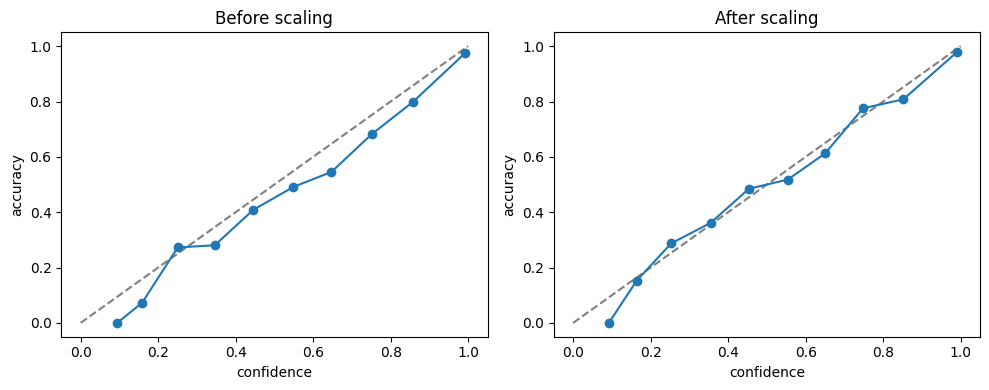

In [8]:
def ece(probs, labels, bins=15):
    conf = probs.max(1)
    correct = probs.argmax(1) == labels
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return total


def predict(probs, threshold=0.0):
    pred = probs.argmax(1)
    return np.where(probs.max(1) < threshold, OOS_ID, pred)


def scores(probs, labels, threshold=0.0):
    pred = predict(probs, threshold)
    ins = labels != OOS_ID
    flagged = pred == OOS_ID
    return {
        "overall_acc": float((pred == labels).mean()),
        "in_scope_acc": float((pred[ins] == labels[ins]).mean()),
        "oos_recall": float((pred[~ins] == OOS_ID).mean()),
        "oos_precision": float((labels[flagged] == OOS_ID).mean()) if flagged.any() else 0.0,
    }


def show(name, s):
    print(f"{name:<22} " + "  ".join(f"{k}={v:.4f}" for k, v in s.items()))


show("test raw", scores(test_raw, test_labels))
show("test scaled", scores(test_probs, test_labels))
print(f"ECE raw={ece(test_raw, test_labels):.4f}  scaled={ece(test_probs, test_labels):.4f}")


def reliability(ax, probs, labels, title, bins=10):
    conf = probs.max(1)
    correct = probs.argmax(1) == labels
    edges = np.linspace(0, 1, bins + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            xs.append(conf[m].mean())
            ys.append(correct[m].mean())
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.plot(xs, ys, "o-")
    ax.set_title(title)
    ax.set_xlabel("confidence")
    ax.set_ylabel("accuracy")


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
reliability(axes[0], test_raw, test_labels, "Before scaling")
reliability(axes[1], test_probs, test_labels, "After scaling")
plt.tight_layout()
plt.show()

Best threshold (chosen on validation): 0.65
test @ 0.0             overall_acc=0.9018  in_scope_acc=0.9622  oos_recall=0.6300  oos_precision=0.9692
test @ 0.65            overall_acc=0.9356  in_scope_acc=0.9464  oos_recall=0.8870  oos_precision=0.8376


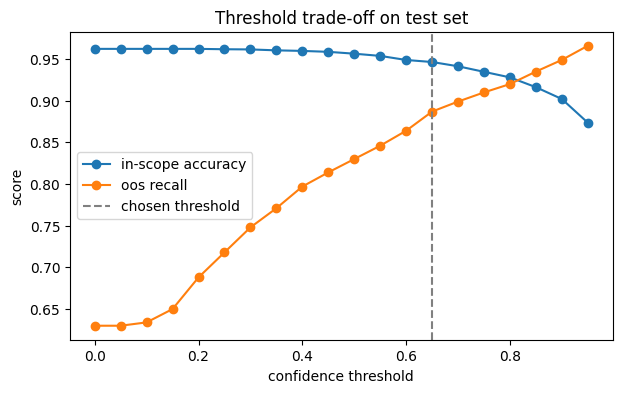

In [9]:
thresholds = np.round(np.arange(0.0, 0.96, 0.05), 2)
val_curve = [scores(val_probs, val_labels, t) for t in thresholds]
test_curve = [scores(test_probs, test_labels, t) for t in thresholds]

balanced = [(s["in_scope_acc"] + s["oos_recall"]) / 2 for s in val_curve]
BEST_THRESHOLD = float(thresholds[int(np.argmax(balanced))])
print("Best threshold (chosen on validation):", BEST_THRESHOLD)
show("test @ 0.0", scores(test_probs, test_labels, 0.0))
show(f"test @ {BEST_THRESHOLD}", scores(test_probs, test_labels, BEST_THRESHOLD))

plt.figure(figsize=(7, 4))
plt.plot(thresholds, [s["in_scope_acc"] for s in test_curve], "o-", label="in-scope accuracy")
plt.plot(thresholds, [s["oos_recall"] for s in test_curve], "o-", label="oos recall")
plt.axvline(BEST_THRESHOLD, color="gray", linestyle="--", label="chosen threshold")
plt.xlabel("confidence threshold")
plt.ylabel("score")
plt.title("Threshold trade-off on test set")
plt.legend()
plt.show()

In [10]:
test_texts = raw["test"]["text"]
test_pred = predict(test_probs, BEST_THRESHOLD)
test_conf = test_probs.max(1)

pairs = Counter(
    (ID2LABEL[t], ID2LABEL[p]) for t, p in zip(test_labels, test_pred) if t != p
)
print("Most common mistakes (true -> predicted):")
for (t, p), n in pairs.most_common(10):
    print(f"{n:>3}x  {t:<25} -> {p}")

wrong = np.where(test_pred != test_labels)[0]
confident_wrong = wrong[np.argsort(-test_conf[wrong])][:10]
print("\nMost confident mistakes:")
for i in confident_wrong:
    print(f"p={test_conf[i]:.3f}  true={ID2LABEL[test_labels[i]]:<22} pred={ID2LABEL[test_pred[i]]:<22} {test_texts[i]}")

Most common mistakes (true -> predicted):
  8x  oos                       -> order
  7x  report_fraud              -> oos
  7x  bill_balance              -> oos
  6x  pto_request_status        -> oos
  5x  transactions              -> spending_history
  5x  how_busy                  -> oos
  5x  pin_change                -> oos
  5x  oos                       -> travel_suggestion
  5x  oos                       -> directions
  5x  oos                       -> current_location

Most confident mistakes:
p=1.000  true=timezone               pred=time                   what time is it in phoenix
p=0.999  true=share_location         pred=current_location       what is my current location
p=0.999  true=expiration_date        pred=replacement_card_duration when will my new credit card arrive
p=0.999  true=oos                    pred=order_status           check the status of my amazon orders for me
p=0.999  true=replacement_card_duration pred=new_card               how can i request a new cre

In [12]:
router_model = trainer.model.eval()


def route(text, top_k=3):
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(router_model.device)
    with torch.no_grad():
        logits = router_model(**enc).logits[0].float().cpu().numpy()
    probs = softmax(logits / TEMPERATURE)
    top = np.argsort(-probs)[:top_k]
    choice = ID2LABEL[int(top[0])] if probs[top[0]] >= BEST_THRESHOLD else "oos"
    return choice, [(ID2LABEL[int(i)], round(float(probs[i]), 4)) for i in top]


for q in [
    "how much money is in my checking account",
    "book me a table for two at 8 tonight",
    "is there a hostel for girls",
    "what's the best way to learn guitar",
    "my card got declined at the store",
]:
    choice, top = route(q)
    print(f"{q:<45} -> {choice:<22} {top}")

trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

how much money is in my checking account      -> balance                [('balance', 0.9989), ('account_blocked', 0.0002), ('interest_rate', 0.0001)]
book me a table for two at 8 tonight          -> restaurant_reservation [('restaurant_reservation', 0.9992), ('cancel_reservation', 0.0002), ('how_busy', 0.0001)]
is there a hostel for girls                   -> oos                    [('schedule_meeting', 0.1639), ('oos', 0.1437), ('book_hotel', 0.1029)]
what's the best way to learn guitar           -> oos                    [('oos', 0.9985), ('recipe', 0.0004), ('play_music', 0.0002)]
my card got declined at the store             -> card_declined          [('card_declined', 0.999), ('report_lost_card', 0.0001), ('damaged_card', 0.0001)]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/clinc_router/tokenizer_config.json',
 '/kaggle/working/clinc_router/tokenizer.json')

In [13]:
for i in range(0, NUM_LABELS, 6):
    print("  ".join(f"{n:<24}" for n in LABEL_NAMES[i:i + 6]))

restaurant_reviews        nutrition_info            account_blocked           oil_change_how            time                      weather                 
redeem_rewards            interest_rate             gas_type                  accept_reservations       smart_home                user_name               
report_lost_card          repeat                    whisper_mode              what_are_your_hobbies     order                     jump_start              
schedule_meeting          meeting_schedule          freeze_account            what_song                 meaning_of_life           restaurant_reservation  
traffic                   make_call                 text                      bill_balance              improve_credit_score      change_language         
no                        measurement_conversion    timer                     flip_coin                 do_you_have_pets          balance                 
tell_joke                 last_maintenance          exchange_rate     

In [14]:
my_queries = [
    "whats my acount balance",
    "i lost my card yesterday",
    "can you convert 100 dollars to rupees",
    "set an alarm for 6am",
    "whats the weather like in lahore",
    "book a flight to dubai next week",
    "how do i fix my car engine",
    "tell me about admission fees",
    "fees?",
    "i want to cancel",
]

for q in my_queries:
    choice, top = route(q)
    flag = "  <- unsure" if top[0][1] < BEST_THRESHOLD else ""
    print(f"{q:<42} -> {choice:<22} {top[0][1]:.3f}{flag}")

whats my acount balance                    -> oos                    0.595  <- unsure
i lost my card yesterday                   -> report_lost_card       0.993
can you convert 100 dollars to rupees      -> exchange_rate          0.997
set an alarm for 6am                       -> alarm                  1.000
whats the weather like in lahore           -> weather                0.994
book a flight to dubai next week           -> book_flight            0.979
how do i fix my car engine                 -> oos                    0.597  <- unsure
tell me about admission fees               -> oos                    0.082  <- unsure
fees?                                      -> greeting               0.869
i want to cancel                           -> cancel                 0.984


In [14]:
import re
import itertools
from collections import defaultdict
from datasets import Dataset, concatenate_datasets

ROWS = ["qwertyuiop", "asdfghjkl", "zxcvbnm"]
STOP = set(
    "the a an and or to of for in on at is are was be my me i you your can could would will "
    "please what whats how do does it this that with from have has get tell need want know "
    "about there some any".split()
)


def neighbors(c):
    for row in ROWS:
        i = row.find(c)
        if i >= 0:
            return [row[j] for j in (i - 1, i + 1) if 0 <= j < len(row)]
    return []


def typo_word(w, r):
    i = r.randrange(1, len(w) - 1)
    op = r.choice(["swap", "delete", "double", "neighbor"])
    if op == "swap":
        return w[:i] + w[i + 1] + w[i] + w[i + 2:]
    if op == "delete":
        return w[:i] + w[i + 1:]
    if op == "double":
        return w[:i] + w[i] + w[i:]
    near = neighbors(w[i].lower())
    return w[:i] + r.choice(near) + w[i + 1:] if near else w


def add_typos(text, r, max_typos=2):
    words = text.split()
    idx = [i for i, w in enumerate(words) if len(w) >= 4 and w.isalpha()]
    if not idx:
        return text
    for i in r.sample(idx, min(len(idx), r.randint(1, max_typos))):
        words[i] = typo_word(words[i], r)
    return " ".join(words)


def distinctive_words(texts_by_label, top_n=4, min_count=3):
    total, per = Counter(), {}
    for lab, texts in texts_by_label.items():
        c = Counter(
            w for t in texts for w in re.findall(r"[a-z]+", t.lower()) if len(w) >= 3 and w not in STOP
        )
        per[lab] = c
        total.update(c)
    out = {}
    for lab, c in per.items():
        ranked = sorted(c, key=lambda w: -(c[w] / total[w]) * np.log1p(c[w]))
        out[lab] = [w for w in ranked if c[w] >= min_count][:top_n]
    return out


def short_forms(lab):
    kw = KEYWORDS[lab]
    forms = set()
    if lab != OOS_ID:
        name = ID2LABEL[lab].replace("_", " ")
        forms |= {name, name + "?"}
    for w in kw:
        forms |= {w, w + "?"}
    for a, b in itertools.combinations(kw[:3], 2):
        forms.add(f"{a} {b}")
    return forms


A_TRAINER = trainer
rng = random.Random(SEED)
train_texts = list(raw["train"]["text"])
train_labels = list(raw["train"]["label"])

by_label = defaultdict(list)
for t, l in zip(train_texts, train_labels):
    by_label[l].append(t)
KEYWORDS = distinctive_words(by_label)

short_rows = [(f, lab) for lab in range(NUM_LABELS) for f in short_forms(lab)]
text_counts = Counter(t for t, _ in short_rows)
short_rows = [(t, l) for t, l in short_rows if text_counts[t] == 1]
short_rows += [(add_typos(t, rng), l) for t, l in short_rows]

typo_idx = rng.sample(range(len(train_texts)), int(0.3 * len(train_texts)))
typo_rows = [(add_typos(train_texts[i], rng), train_labels[i]) for i in typo_idx]
typo_rows = [(t, l) for (t, l), i in zip(typo_rows, typo_idx) if t != train_texts[i]]

aug_rows = typo_rows + short_rows
aug_ds = Dataset.from_dict(
    {"text": [t for t, _ in aug_rows], "label": [l for _, l in aug_rows]},
    features=raw["train"].features,
)
train_aug_raw = concatenate_datasets([raw["train"], aug_ds]).shuffle(seed=SEED)

test_rng = random.Random(123)
typo_test_raw = Dataset.from_dict(
    {"text": [add_typos(t, test_rng) for t in raw["test"]["text"]], "label": list(raw["test"]["label"])},
    features=raw["test"].features,
)

print(f"original train: {len(raw['train'])}  typo copies: {len(typo_rows)}  short forms: {len(short_rows)}  total: {len(train_aug_raw)}")
print("\nTypo examples:")
for i in range(5):
    print(f"  {train_texts[typo_idx[i]]:<50} -> {typo_rows[i][0]}")
print("\nShort form examples:")
for t, l in rng.sample(short_rows, 10):
    print(f"  {t:<30} -> {ID2LABEL[l]}")

original train: 15250  typo copies: 4503  short forms: 3490  total: 23243

Typo examples:
  has anyone approved my day off request             -> has anyoone apporved my day off request
  are vaccinations required to travel there          -> are vaccinations required to trsvel there
  get me a room in cali on november 11 to 15         -> get me a roim in cali on november 11 to 15
  is there anything i can't ask you                  -> is three anything i can't ask you
  can u please set the timer for 5 minutes           -> can u plese set the timer for 5 minuyes

Short form examples:
  mpg highway                    -> mpg
  pto balance                    -> pto_balance
  reset                          -> reset_settings
  messaeg him                    -> text
  funny jokws                    -> tell_joke
  what can i ask you             -> what_can_i_ask_you
  reasons                        -> w2
  fip coiin                      -> flip_coin
  christtie rpbby                -> make_ca

In [15]:
def tok(ds):
    return ds.map(
        lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN),
        batched=True,
        remove_columns=["text"],
    )


train_aug_ds = tok(train_aug_raw)
typo_test_ds = tok(typo_test_raw)

model_b = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)

args_b = TrainingArguments(
    output_dir="/kaggle/working/checkpoints_aug",
    num_train_epochs=5,
    learning_rate=5e-5,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=128,
    warmup_steps=0.1,
    weight_decay=0.01,
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

B_TRAINER = Trainer(
    model=model_b,
    args=args_b,
    train_dataset=train_aug_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

B_TRAINER.train()

Map:   0%|          | 0/23243 [00:00<?, ? examples/s]

Map:   0%|          | 0/5500 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': None, 'bos_token_id': None}.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.487080,0.260428,0.931935
2,0.177039,0.203426,0.951935
3,0.050059,0.201486,0.955484
4,0.005876,0.189038,0.957742
5,0.002698,0.192455,0.959677


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1820, training_loss=0.46684242787433194, metrics={'train_runtime': 320.0256, 'train_samples_per_second': 363.143, 'train_steps_per_second': 5.687, 'total_flos': 1777265539167330.0, 'train_loss': 0.46684242787433194, 'epoch': 5.0})

In [16]:
import pandas as pd


def logits_of(tr, ds):
    out = tr.predict(ds)
    return np.asarray(out.predictions, dtype=np.float32), out.label_ids


def best_threshold(probs, labels):
    ts = np.round(np.arange(0.0, 0.96, 0.05), 2)
    bal = [(s["in_scope_acc"] + s["oos_recall"]) / 2 for s in (scores(probs, labels, t) for t in ts)]
    return float(ts[int(np.argmax(bal))])


def evaluate(tr):
    vl, vy = logits_of(tr, val_ds)
    t = fit_temperature(vl, vy)
    thr = best_threshold(softmax(vl / t, axis=1), vy)
    res = {}
    for split, ds in [("clean", test_ds), ("typos", typo_test_ds)]:
        lg, y = logits_of(tr, ds)
        p = softmax(lg / t, axis=1)
        s = scores(p, y, thr)
        s["ece"] = float(ece(p, y))
        res[split] = s
    return t, thr, res


A_T, A_THR, A_RES = evaluate(A_TRAINER)
B_T, B_THR, B_RES = evaluate(B_TRAINER)

print(f"Model A: temperature={A_T:.3f}  threshold={A_THR}")
print(f"Model B: temperature={B_T:.3f}  threshold={B_THR}\n")

table = pd.DataFrame({
    "A clean": A_RES["clean"],
    "B clean": B_RES["clean"],
    "A typos": A_RES["typos"],
    "B typos": B_RES["typos"],
}).round(4)
print(table)

Model A: temperature=31.562  threshold=0.05
Model B: temperature=1.174  threshold=0.85

               A clean  B clean  A typos  B typos
overall_acc     0.1818   0.9218   0.1818   0.8013
in_scope_acc    0.0000   0.9198   0.0000   0.7707
oos_recall      1.0000   0.9310   1.0000   0.9390
oos_precision   0.1818   0.7430   0.1818   0.4966
ece             0.0007   0.0212   0.0000   0.0284


In [18]:
import shutil
shutil.rmtree(OUTPUT_DIR, ignore_errors=True)
print("Deleted:", OUTPUT_DIR)

Deleted: /kaggle/working/clinc_router


In [19]:
A_TRAINER = trainer
print(trainer.evaluate())

{'eval_loss': 5.135182857513428, 'eval_accuracy': 0.008709677419354838}


In [20]:
model_a = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)

args_a = TrainingArguments(
    output_dir="/kaggle/working/checkpoints_a_fresh",
    num_train_epochs=5,
    learning_rate=5e-5,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=128,
    warmup_steps=0.1,
    weight_decay=0.01,
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

A_TRAINER = Trainer(
    model=model_a,
    args=args_a,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

A_TRAINER.train()
print(A_TRAINER.evaluate())
A_TRAINER.save_model(OUTPUT_DIR)

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': None, 'bos_token_id': None}.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.469806,0.342229,0.911935
2,0.108429,0.246917,0.940968
3,0.019160,0.199429,0.956774
4,0.009050,0.185888,0.960000
5,0.000988,0.186427,0.959677


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy
0.000988,0.185888,5,0.960000


{'eval_loss': 0.18588772416114807, 'eval_accuracy': 0.96}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [21]:
def route_with(tr, t, thr, text):
    m = tr.model.eval()
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(m.device)
    with torch.no_grad():
        logits = m(**enc).logits[0].float().cpu().numpy()
    probs = softmax(logits / t)
    best = int(probs.argmax())
    label = ID2LABEL[best] if probs[best] >= thr else "oos"
    return label, ID2LABEL[best], float(probs[best])


compare_queries = [
    "whats my acount balance",
    "i lost my card yesterday",
    "can you convert 100 dollars to rupees",
    "set an alarm for 6am",
    "whats the weather like in lahore",
    "book a flight to dubai next week",
    "how do i fix my car engine",
    "tell me about admission fees",
    "fees?",
    "i want to cancel",
    "balance?",
    "lost card",
    "trnasfer money to my savings",
    "credit scor",
]

print(f"{'query':<40} {'model A':<32} {'model B':<32}")
for q in compare_queries:
    a_lab, a_top, a_p = route_with(A_TRAINER, A_T, A_THR, q)
    b_lab, b_top, b_p = route_with(B_TRAINER, B_T, B_THR, q)
    a = f"{a_lab} ({a_top} {a_p:.2f})" if a_lab == "oos" else f"{a_lab} {a_p:.2f}"
    b = f"{b_lab} ({b_top} {b_p:.2f})" if b_lab == "oos" else f"{b_lab} {b_p:.2f}"
    print(f"{q:<40} {a:<32} {b:<32}")

B_TRAINER.save_model("/kaggle/working/clinc_router_aug")

query                                    model A                          model B                         
whats my acount balance                  oos (balance 0.01)               balance 0.99                    
i lost my card yesterday                 oos (report_lost_card 0.01)      report_lost_card 0.93           
can you convert 100 dollars to rupees    oos (exchange_rate 0.01)         exchange_rate 1.00              
set an alarm for 6am                     oos (alarm 0.01)                 alarm 1.00                      
whats the weather like in lahore         oos (weather 0.01)               weather 1.00                    
book a flight to dubai next week         oos (book_flight 0.01)           book_flight 1.00                
how do i fix my car engine               oos (jump_start 0.01)            oos (jump_start 0.63)           
tell me about admission fees             oos (reminder 0.01)              oos (international_fees 0.55)   
fees?                                

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [22]:
print(A_T, A_THR)

31.561616897583008 0.05


In [37]:
import pandas as pd


def logits_of(tr, ds):
    out = tr.predict(ds)
    return np.asarray(out.predictions, dtype=np.float32), out.label_ids


def best_threshold(probs, labels):
    ts = np.round(np.arange(0.0, 0.96, 0.05), 2)
    bal = [(s["in_scope_acc"] + s["oos_recall"]) / 2 for s in (scores(probs, labels, t) for t in ts)]
    return float(ts[int(np.argmax(bal))])


def evaluate(tr):
    vl, vy = logits_of(tr, val_ds)
    t = fit_temperature(vl, vy)
    thr = best_threshold(softmax(vl / t, axis=1), vy)
    res = {}
    for split, ds in [("clean", test_ds), ("typos", typo_test_ds)]:
        lg, y = logits_of(tr, ds)
        p = softmax(lg / t, axis=1)
        s = scores(p, y, thr)
        s["ece"] = float(ece(p, y))
        res[split] = s
    return t, thr, res


def route_with(tr, t, thr, text):
    m = tr.model.eval()
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(m.device)
    with torch.no_grad():
        logits = m(**enc).logits[0].float().cpu().numpy()
    probs = softmax(logits / t)
    best = int(probs.argmax())
    label = ID2LABEL[best] if probs[best] >= thr else "oos"
    return label, ID2LABEL[best], float(probs[best])


A_T, A_THR, A_RES = evaluate(A_TRAINER)
B_T, B_THR, B_RES = evaluate(B_TRAINER)

print(f"Model A: temperature={A_T:.3f}  threshold={A_THR}")
print(f"Model B: temperature={B_T:.3f}  threshold={B_THR}\n")

table = pd.DataFrame({
    "A clean": A_RES["clean"],
    "B clean": B_RES["clean"],
    "A typos": A_RES["typos"],
    "B typos": B_RES["typos"],
}).round(4)
print(table, "\n")

compare_queries = [
    "whats my acount balance",
    "i lost my card yesterday",
    "can you convert 100 dollars to rupees",
    "set an alarm for 6am",
    "whats the weather like in lahore",
    "book a flight to dubai next week",
    "how do i fix my car engine",
    "tell me about admission fees",
    "fees?",
    "i want to cancel",
    "balance?",
    "lost card",
    "trnasfer money to my savings",
    "credit scor",
]

print(f"{'query':<40} {'model A':<32} {'model B':<32}")
for q in compare_queries:
    a_lab, a_top, a_p = route_with(A_TRAINER, A_T, A_THR, q)
    b_lab, b_top, b_p = route_with(B_TRAINER, B_T, B_THR, q)
    a = f"{a_lab} ({a_top} {a_p:.2f})" if a_lab == "oos" else f"{a_lab} {a_p:.2f}"
    b = f"{b_lab} ({b_top} {b_p:.2f})" if b_lab == "oos" else f"{b_lab} {b_p:.2f}"
    print(f"{q:<40} {a:<32} {b:<32}")

Model A: temperature=1.154  threshold=0.85
Model B: temperature=1.174  threshold=0.85

               A clean  B clean  A typos  B typos
overall_acc     0.9216   0.9218   0.7004   0.8013
in_scope_acc    0.9216   0.9198   0.6462   0.7707
oos_recall      0.9220   0.9310   0.9440   0.9390
oos_precision   0.7557   0.7430   0.3928   0.4966
ece             0.0216   0.0212   0.0518   0.0284 

query                                    model A                          model B                         
whats my acount balance                  balance 0.96                     balance 0.99                    
i lost my card yesterday                 report_lost_card 0.94            report_lost_card 0.93           
can you convert 100 dollars to rupees    exchange_rate 1.00               exchange_rate 1.00              
set an alarm for 6am                     alarm 1.00                       alarm 1.00                      
whats the weather like in lahore         weather 1.00                     we

In [38]:
TEST_SUITE = {
    "clean": [
        ("how much money do i have in checking", "balance"),
        ("i misplaced my credit card", "report_lost_card"),
        ("what's 20 euros in dollars", "exchange_rate"),
        ("wake me up at 7 tomorrow", "alarm"),
        ("will it rain today", "weather"),
        ("i need a plane ticket to london", "book_flight"),
        ("move 500 dollars from checking to savings", "transfer"),
        ("what is my credit score", "credit_score"),
        ("tell me something funny", "tell_joke"),
        ("how do you say thank you in french", "translate"),
        ("how many calories are in an apple", "calories"),
        ("set a timer for 10 minutes", "timer"),
    ],
    "typos": [
        ("hw much mony do i hav in checkng", "balance"),
        ("i lsot my crdit card", "report_lost_card"),
        ("convrt 50 dolars to euros", "exchange_rate"),
        ("set alrm for 7am", "alarm"),
        ("whats the wether tomorow", "weather"),
        ("bok a flite to paris", "book_flight"),
        ("trasnfer 200 to my savngs", "transfer"),
        ("chek my credt score", "credit_score"),
        ("tel me a jok", "tell_joke"),
        ("set a timr for 5 minuts", "timer"),
    ],
    "short": [
        ("balance", "balance"),
        ("weather?", "weather"),
        ("alarm 7am", "alarm"),
        ("joke", "tell_joke"),
        ("transfer money", "transfer"),
        ("flight status", "flight_status"),
        ("calories banana", "calories"),
        ("timer 5 min", "timer"),
    ],
    "out_of_scope": [
        ("how do i learn python", "oos"),
        ("who won the world cup", "oos"),
        ("tell me about admission fees", "oos"),
        ("write me a poem about rain", "oos"),
        ("recommend a good laptop", "oos"),
        ("how do i fix my car engine", "oos"),
        ("is there a hostel for girls", "oos"),
        ("what is the best diet for weight loss", "oos"),
    ],
}

AMBIGUOUS = ["fees?", "card", "i want to cancel", "help", "account", "money"]

missing = {e for items in TEST_SUITE.values() for _, e in items} - set(LABEL2ID)
assert not missing, f"Unknown labels: {missing}"

summary = []
for category, items in TEST_SUITE.items():
    print(f"\n=== {category.upper()} ===")
    print(f"{'query':<42} {'expected':<18} {'model A':<26} {'model B':<26}")
    a_ok = b_ok = 0
    for q, expected in items:
        a_lab, _, a_p = route_with(A_TRAINER, A_T, A_THR, q)
        b_lab, _, b_p = route_with(B_TRAINER, B_T, B_THR, q)
        a_hit, b_hit = a_lab == expected, b_lab == expected
        a_ok += a_hit
        b_ok += b_hit
        a = f"{'✓' if a_hit else '✗'} {a_lab} {a_p:.2f}"
        b = f"{'✓' if b_hit else '✗'} {b_lab} {b_p:.2f}"
        print(f"{q:<42} {expected:<18} {a:<26} {b:<26}")
    summary.append((category, len(items), a_ok, b_ok))

print("\n=== AMBIGUOUS (lower confidence is better) ===")
print(f"{'query':<42} {'model A':<32} {'model B':<32}")
a_conf, b_conf = [], []
for q in AMBIGUOUS:
    a_lab, a_top, a_p = route_with(A_TRAINER, A_T, A_THR, q)
    b_lab, b_top, b_p = route_with(B_TRAINER, B_T, B_THR, q)
    a_conf.append(a_p)
    b_conf.append(b_p)
    print(f"{q:<42} {a_top + ' ' + format(a_p, '.2f'):<32} {b_top + ' ' + format(b_p, '.2f'):<32}")

print("\n=== FINAL SCOREBOARD ===")
print(f"{'category':<15} {'model A':>10} {'model B':>10}")
total_n = total_a = total_b = 0
for category, n, a_ok, b_ok in summary:
    print(f"{category:<15} {a_ok:>5}/{n:<4} {b_ok:>5}/{n:<4}")
    total_n += n
    total_a += a_ok
    total_b += b_ok
print(f"{'TOTAL':<15} {total_a:>5}/{total_n:<4} {total_b:>5}/{total_n:<4}")
print(f"{'accuracy':<15} {total_a / total_n:>10.1%} {total_b / total_n:>10.1%}")
print(f"{'ambiguous avg':<15} {np.mean(a_conf):>10.2f} {np.mean(b_conf):>10.2f}   (confidence, lower is more honest)")


=== CLEAN ===
query                                      expected           model A                    model B                   
how much money do i have in checking       balance            ✓ balance 1.00             ✓ balance 1.00            
i misplaced my credit card                 report_lost_card   ✗ oos 0.81                 ✗ oos 0.56                
what's 20 euros in dollars                 exchange_rate      ✓ exchange_rate 1.00       ✓ exchange_rate 1.00      
wake me up at 7 tomorrow                   alarm              ✓ alarm 0.99               ✓ alarm 0.99              
will it rain today                         weather            ✓ weather 0.99             ✓ weather 1.00            
i need a plane ticket to london            book_flight        ✗ oos 0.84                 ✓ book_flight 1.00        
move 500 dollars from checking to savings  transfer           ✓ transfer 1.00            ✓ transfer 1.00           
what is my credit score                    credit_score  